# Gradient Descent, Step by Step

*By Shikha Pallavi*

How does a model find the bottom of its cost curve without trying every value? It feels the slope and takes small steps downhill. In this notebook we do exactly that on a tiny dataset, so every number can be checked by hand.

> ## 📖 Read the full series: [Machine Learning Basics](https://shikhapallavi123.github.io/ml-basics/)
> This notebook is the hands-on companion to **Part 5**. Read the post for the interactive version, then run the code here.
> [Part 1: Foundations](https://shikhapallavi123.github.io/ml-basics/part-1-foundations.html) · [Part 2: Supervised Learning](https://shikhapallavi123.github.io/ml-basics/part-2-supervised-learning.html) · [Part 3: Linear Regression](https://shikhapallavi123.github.io/ml-basics/part-3-linear-regression.html) · [Part 4: Fast Gradient Descent](https://shikhapallavi123.github.io/ml-basics/part-4-fast-gradient-descent.html) · [Part 5: Gradient Descent Step by Step](https://shikhapallavi123.github.io/ml-basics/part-5-gradient-descent.html)

**What you'll see**
1. The cost J(θ) at θ₁ = 1, 2 and 3, computed by hand and by code
2. The cost curve and its global minimum
3. The slope, and a check that our formula for it is right
4. The update rule θ₁ := θ₁ − α · slope, one step at a time
5. How the learning rate α changes everything

## 1. The data and the cost

Three points on a line: (1, 2), (2, 4), (3, 6). We fix θ₀ = 0, so the model is `h(x) = θ₁ · x`. The cost is

```
J(θ) = 1/(2m) · Σ ( h(x) − y )²        with m = 3
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([1.0, 2.0, 3.0])
y = np.array([2.0, 4.0, 6.0])
m = len(x)

def cost(theta1):
    errors = theta1 * x - y
    return (errors ** 2).sum() / (2 * m)

print("theta1   errors            cost J")
for t in (1, 2, 3):
    print(f"{t:>6}   {str((t * x - y).tolist()):<17} {cost(t):.4f}")
print()
print("By hand at theta1 = 1:  (1 + 4 + 9) / 6 =", round(14 / 6, 4))

theta1   errors            cost J
     1   [-1.0, -2.0, -3.0] 2.3333
     2   [0.0, 0.0, 0.0]   0.0000
     3   [1.0, 2.0, 3.0]   2.3333

By hand at theta1 = 1:  (1 + 4 + 9) / 6 = 2.3333


Exact values: J(1) = J(3) = 14/6 ≈ **2.333**, and J(2) = **0**. At θ₁ = 2 the line passes through every point, so every error is zero.

## 2. The cost curve: a bowl with one bottom

Plot J against θ₁. For linear regression this is a smooth bowl, and the lowest point is the **global minimum**.

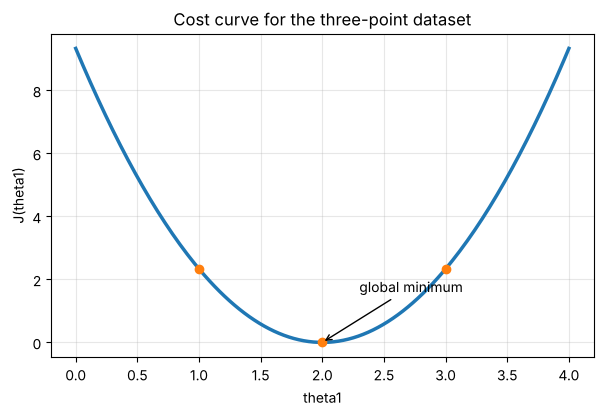

In [2]:
grid = np.linspace(0, 4, 200)
plt.figure(figsize=(7, 4.2))
plt.plot(grid, [cost(t) for t in grid], color="tab:blue", linewidth=2.5)
plt.scatter([1, 2, 3], [cost(1), cost(2), cost(3)], color="tab:orange", zorder=3)
plt.annotate("global minimum", xy=(2, 0), xytext=(2.3, 1.6), arrowprops=dict(arrowstyle="->"))
plt.xlabel("theta1")
plt.ylabel("J(theta1)")
plt.title("Cost curve for the three-point dataset")
plt.grid(alpha=0.3)
plt.show()

## 3. The slope

The slope of J tells us which way is downhill. Working out the derivative for this dataset gives

```
dJ/dθ₁ = (1/m) · Σ (θ₁·x − y)·x  =  (14/3) · (θ₁ − 2)
```

Never trust a formula you have not checked. We compare it with a numerical slope (a tiny step either side):

In [3]:
def slope(theta1):
    return ((theta1 * x - y) * x).sum() / m

def numeric_slope(theta1, eps=1e-6):
    return (cost(theta1 + eps) - cost(theta1 - eps)) / (2 * eps)

for t in (0.5, 1.0, 2.0, 3.5):
    print(f"theta1 = {t:<4}  formula slope = {slope(t):>8.4f}   numeric slope = {numeric_slope(t):>8.4f}")

theta1 = 0.5   formula slope =  -7.0000   numeric slope =  -7.0000
theta1 = 1.0   formula slope =  -4.6667   numeric slope =  -4.6667
theta1 = 2.0   formula slope =   0.0000   numeric slope =   0.0000
theta1 = 3.5   formula slope =   7.0000   numeric slope =   7.0000


- **Negative slope** (left of the minimum): the curve goes down to the right, so we should *increase* θ₁.
- **Positive slope** (right of the minimum): we should *decrease* θ₁.
- **Zero slope** at the bottom: stop.

One rule covers all three, the **gradient descent update**:

```
θ₁ := θ₁ − α · slope
```

α is the **learning rate**, the size of each step.

## 4. Walk down the bowl

Start at θ₁ = 0.5 with α = 0.2 and print every step, so you can follow the arithmetic.

In [4]:
def walk(theta1, alpha, steps):
    path = [theta1]
    for _ in range(steps):
        theta1 = theta1 - alpha * slope(theta1)
        path.append(theta1)
    return np.array(path)

theta, alpha = 0.5, 0.2
print(f"alpha = {alpha}")
print(" step    theta1     slope      cost J")
for i in range(8):
    s = slope(theta)
    print(f"{i:>5}  {theta:>8.4f}  {s:>8.4f}  {cost(theta):>9.5f}")
    theta = theta - alpha * s

alpha = 0.2
 step    theta1     slope      cost J
    0    0.5000   -7.0000    5.25000
    1    1.9000   -0.4667    0.02333
    2    1.9933   -0.0311    0.00010
    3    1.9996   -0.0021    0.00000
    4    2.0000   -0.0001    0.00000
    5    2.0000   -0.0000    0.00000
    6    2.0000   -0.0000    0.00000
    7    2.0000   -0.0000    0.00000


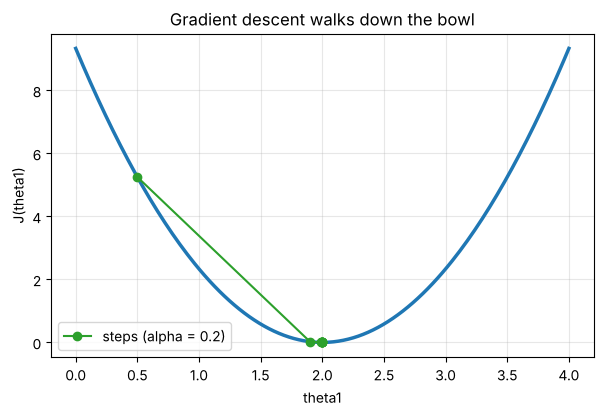

In [5]:
path = walk(0.5, 0.2, 8)
plt.figure(figsize=(7, 4.2))
plt.plot(grid, [cost(t) for t in grid], color="tab:blue", linewidth=2.5)
plt.plot(path, [cost(t) for t in path], "o-", color="tab:green", label="steps (alpha = 0.2)")
plt.xlabel("theta1")
plt.ylabel("J(theta1)")
plt.title("Gradient descent walks down the bowl")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. The learning rate decides

We run the same start (θ₁ = 0.5) for 20 steps with four values of α.

 alpha   theta1 after 20 steps      cost J
  0.02                   1.7886         0.1042
   0.2                   2.0000         0.0000
   0.4                   1.9143         0.0171
   0.5                -471.0053    522045.9943


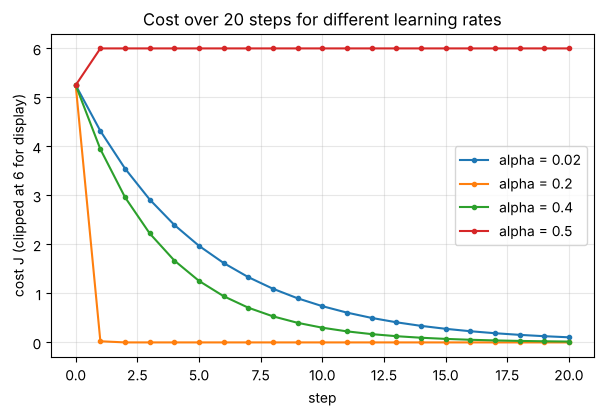

In [6]:
alphas = [0.02, 0.2, 0.4, 0.5]
print(" alpha   theta1 after 20 steps      cost J")
fig, ax = plt.subplots(figsize=(7, 4.2))
for a in alphas:
    p = walk(0.5, a, 20)
    print(f"{a:>6}   {p[-1]:>22.4f}   {cost(p[-1]):>12.4f}")
    ax.plot(range(21), [min(cost(t), 6) for t in p], marker="o", markersize=3, label=f"alpha = {a}")
ax.set_xlabel("step")
ax.set_ylabel("cost J (clipped at 6 for display)")
ax.set_title("Cost over 20 steps for different learning rates")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

- **α = 0.02 (too small):** safe, but after 20 steps it is still short of the bottom. Slow training.
- **α = 0.2 (good):** reaches the bottom quickly.
- **α = 0.4 (big):** jumps from side to side but each jump is smaller, so it still settles.
- **α = 0.5 (too large):** every step overshoots further than the last. It **diverges**.

Why is there a sharp line between 0.4 and 0.5? For this dataset each step multiplies the distance to the minimum by `1 − α · 14/3`. We converge only if that factor stays between −1 and 1:

In [7]:
limit = 2 / (14 / 3)
print(f"Convergence needs alpha < 2 / (14/3) = {limit:.4f}")
for a in (0.4, 0.42, 0.43, 0.44, 0.5):
    factor = 1 - a * 14 / 3
    print(f"alpha = {a:<5} factor = {factor:>7.4f}  ->", "converges" if abs(factor) < 1 else "diverges")

Convergence needs alpha < 2 / (14/3) = 0.4286
alpha = 0.4   factor = -0.8667  -> converges
alpha = 0.42  factor = -0.9600  -> converges
alpha = 0.43  factor = -1.0067  -> diverges
alpha = 0.44  factor = -1.0533  -> diverges
alpha = 0.5   factor = -1.3333  -> diverges


## Key takeaways

- The cost curve for linear regression is a bowl with one bottom, the **global minimum**.
- The **slope** says which way is downhill. The update `θ := θ − α · slope` always steps downhill.
- At the minimum the slope is **zero**, so the steps stop on their own.
- **Too small** an α is slow. **Too large** an α overshoots and can diverge.
- Always check a derivative against a numerical slope before trusting it.

## 📖 Continue the series
**[Read all of Machine Learning Basics →](https://shikhapallavi123.github.io/ml-basics/)**
[Part 1: Foundations](https://shikhapallavi123.github.io/ml-basics/part-1-foundations.html) · [Part 2: Supervised Learning](https://shikhapallavi123.github.io/ml-basics/part-2-supervised-learning.html) · [Part 3: Linear Regression](https://shikhapallavi123.github.io/ml-basics/part-3-linear-regression.html) · [Part 4: Fast Gradient Descent](https://shikhapallavi123.github.io/ml-basics/part-4-fast-gradient-descent.html) · [Part 5: Gradient Descent Step by Step](https://shikhapallavi123.github.io/ml-basics/part-5-gradient-descent.html)

---
*© 2026 Shikha Pallavi. Shared under the Apache 2.0 license. You are welcome to reuse the code. Please credit the author and link back to the Machine Learning Basics series.*